1. n fitting of unperturbed and occluded data
2. introduce parameters and include y_max_g
3. generate possible params (1 params)
4. see how params can change
5. step along delta theta

## 1. n fitting of unperturbed and occluded data


In [86]:
import os
import pickle
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import pandas as pd
import optax
from jaxopt import AndersonAcceleration

m = 2 #mitral count
x = jnp.ones(m) #OSN input

In [87]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

Fixing Hill exponents from Elisa

Fit n and scale per cell class from Elisa's firing rate curves `n_r, n_b, n_g, n_y` 
(firing rates vs injected current)

In [88]:
def nr_full(x, n, b, y_max):
    return nr(x / b, n) * y_max

# Mitral cells

In [89]:
df_mitral_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,G:AB',
    nrows=45
)
#df_mitral_unperturbed

In [90]:
df_mitral_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,AG:BE',
    nrows=45
)
#df_mitral_occluded

# Red cells (ETCs)

In [91]:
df_red_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=4,
    usecols='J,N:AQ',
    nrows=35
).dropna(how='all').astype(float)
#df_red_unperturbed

In [92]:
df_red_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=41,
    usecols='J,N:AQ',
    nrows=73
).dropna(how='all').astype(float)

# Green cells

In [93]:
df_green_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,C:L',
    nrows=51
).dropna(how='all').astype(float)
#df_green_unperturbed

In [94]:
df_green_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,Y:AH',
    nrows=51
).dropna(how='all').astype(float)
#df_green_occluded

# Blue cells

In [95]:
df_blue_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,N:V',
    nrows=51
).dropna(how='all').astype(float)
#df_blue_unperturbed

In [96]:
df_blue_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,AJ:AP',
    nrows=51
).dropna(how='all').astype(float)
#df_blue_occluded

## Summary


Red Neurons
n = 1.850, b = 106.943, y_max = 57.269

Green Neurons
n = 1.868, b = 63.855, y_max = 24.256

Blue Neurons
n = 0.650, b = 38880.228, y_max = 579.160

Mitral Cells
n = 1.560, b = 1403.392, y_max = 444.193


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


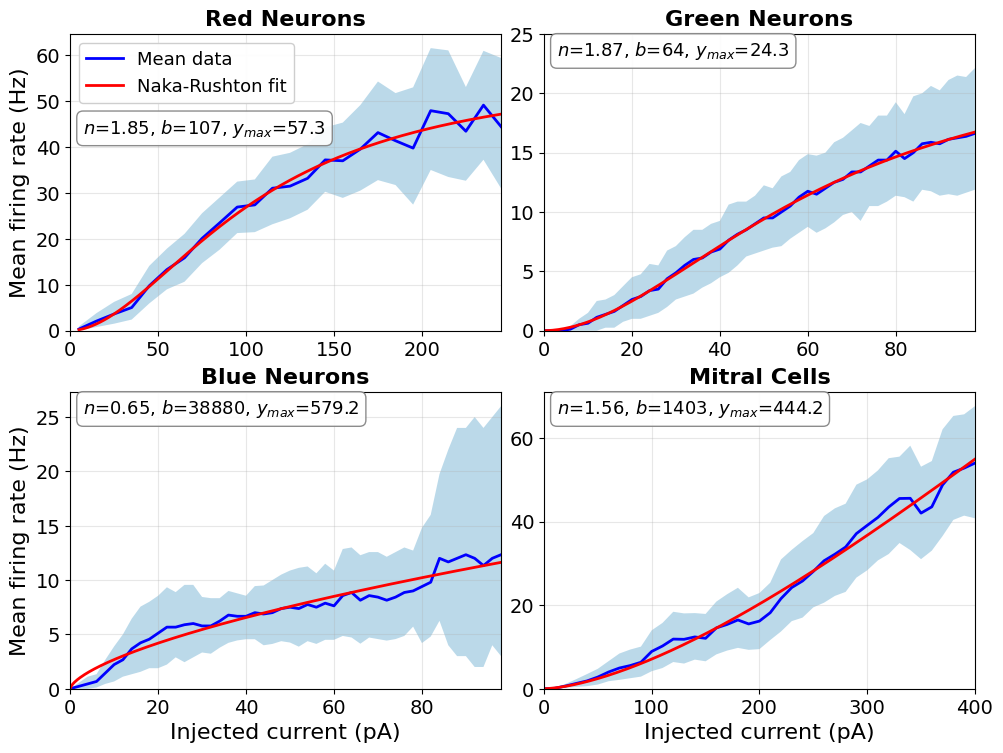

In [97]:
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG, FS_PARAM = 16, 16, 14, 13, 13
param_bbox = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.9)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), sharex=False)
dfs = [
    df_red_unperturbed.iloc[:-5],
    df_green_unperturbed.drop(columns=['B.4', 'D.1']),
    df_blue_unperturbed,
    df_mitral_unperturbed,
]
titles = ['Red Neurons', 'Green Neurons', 'Blue Neurons', 'Mitral Cells']

for i, (df_plot, title) in enumerate(zip(dfs, titles)):
    ax = axes.flat[i]
    x = np.asarray(df_plot.index, dtype=float)
    y = np.asarray(df_plot.mean(axis=1), dtype=float)
    fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100], maxfev=8000)

    print(f"\n{title}")
    print(f"n = {fit_params[0]:.3f}, b = {fit_params[1]:.3f}, y_max = {fit_params[2]:.3f}")

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = nr_full(x_fit, *fit_params)

    df_long = (
        df_plot.reset_index(names='current')
        .melt(id_vars='current', var_name='cell', value_name='firing_rate')
    )
    sns.lineplot(
        data=df_long, x='current', y='firing_rate', ax=ax,
        color='blue', linewidth=2, errorbar=('ci', 95), err_style='band',
        err_kws=dict(facecolor='#9ecae1', alpha=0.7, edgecolor='none'),
        label='Mean data' if i == 0 else None, legend=False,
    )
    ax.plot(
        x_fit, y_fit, color='red', linewidth=2,
        label='Naka-Rushton fit' if i == 0 else '_nolegend_',
    )
    ax.set_title(title, fontsize=FS_TITLE, fontweight='bold')
    ax.set_xlabel('')
    ax.set_xlim(0, x.max())
    y_upper = max(ax.dataLim.ymax, y_fit.max()) * 1.05
    if i == 1:
        y_upper = np.ceil(y_upper / 5) * 5
        ax.set_yticks(np.arange(0, y_upper + 1, 5))
    ax.set_ylim(0, y_upper)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    ax.grid(True, alpha=0.3)

    param_text = (
        f'$n$={fit_params[0]:.2f}, $b$={fit_params[1]:.0f}, '
        f'$y_{{max}}$={fit_params[2]:.1f}'
    )
    if i == 0:
        leg = ax.legend(loc='upper left', fontsize=FS_LEG, framealpha=0.95)
        fig.canvas.draw()
        param_y = leg.get_window_extent().transformed(ax.transAxes.inverted()).y0 - 0.02
    else:
        param_y = 0.98
    ax.text(
        0.03, param_y, param_text, transform=ax.transAxes,
        fontsize=FS_PARAM, va='top', ha='left', bbox=param_bbox,
    )

axes[0, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')
plt.tight_layout(pad=0.6)
plt.savefig('Figures_final/n_fit_all_cells.eps', bbox_inches='tight')
plt.show()


Red Neurons
n = 2.196, b = 84.799, y_max = 44.179

Green Neurons
n = 1.747, b = 75.347, y_max = 14.204

Blue Neurons
n = 2.829, b = 24.242, y_max = 4.981

Mitral Cells
n = 2.069, b = 449.874, y_max = 120.785


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


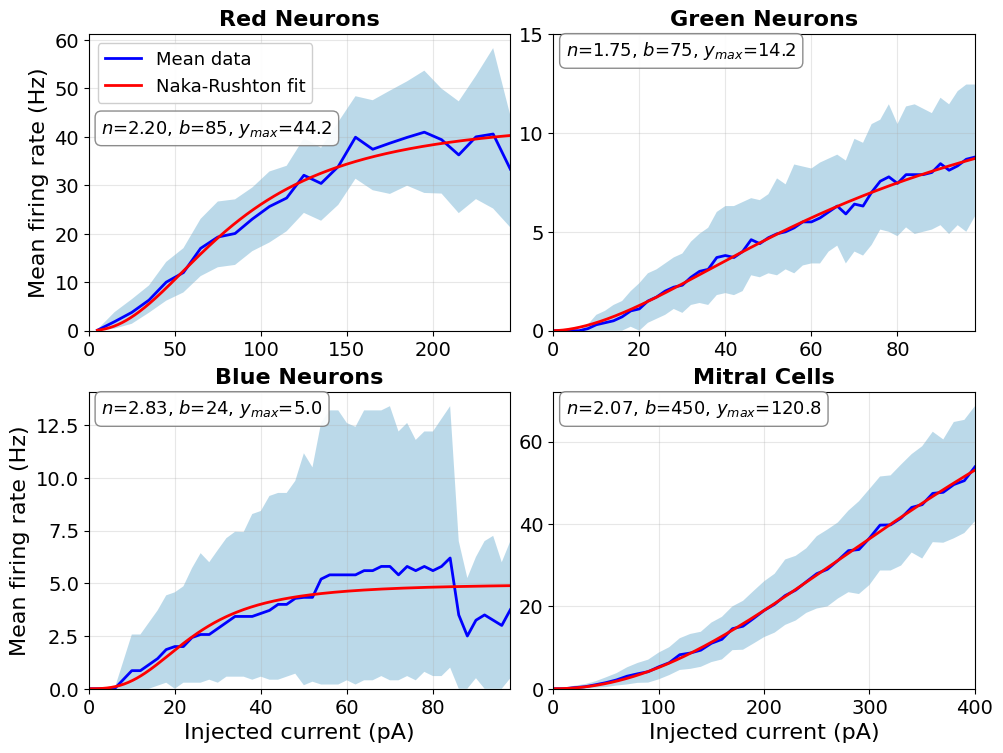

In [98]:
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG, FS_PARAM = 16, 16, 14, 13, 13
param_bbox = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.9)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), sharex=False)
dfs = [
    df_red_occluded.iloc[:-5],
    df_green_occluded,
    df_blue_occluded,
    df_mitral_occluded,
]
titles = ['Red Neurons', 'Green Neurons', 'Blue Neurons', 'Mitral Cells']

for i, (df_plot, title) in enumerate(zip(dfs, titles)):
    ax = axes.flat[i]
    x = np.asarray(df_plot.index, dtype=float)
    y = np.asarray(df_plot.mean(axis=1), dtype=float)
    fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100], maxfev=8000)

    print(f"\n{title}")
    print(f"n = {fit_params[0]:.3f}, b = {fit_params[1]:.3f}, y_max = {fit_params[2]:.3f}")

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = nr_full(x_fit, *fit_params)

    df_long = (
        df_plot.reset_index(names='current')
        .melt(id_vars='current', var_name='cell', value_name='firing_rate')
    )
    sns.lineplot(
        data=df_long, x='current', y='firing_rate', ax=ax,
        color='blue', linewidth=2, errorbar=('ci', 95), err_style='band',
        err_kws=dict(facecolor='#9ecae1', alpha=0.7, edgecolor='none'),
        label='Mean data' if i == 0 else None, legend=False,
    )
    ax.plot(
        x_fit, y_fit, color='red', linewidth=2,
        label='Naka-Rushton fit' if i == 0 else '_nolegend_',
    )
    ax.set_title(title, fontsize=FS_TITLE, fontweight='bold')
    ax.set_xlabel('')
    ax.set_xlim(0, x.max())
    y_upper = max(ax.dataLim.ymax, y_fit.max()) * 1.05
    if i == 1:
        y_upper = np.ceil(y_upper / 5) * 5
        ax.set_yticks(np.arange(0, y_upper + 1, 5))
    ax.set_ylim(0, y_upper)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    ax.grid(True, alpha=0.3)

    param_text = (
        f'$n$={fit_params[0]:.2f}, $b$={fit_params[1]:.0f}, '
        f'$y_{{max}}$={fit_params[2]:.1f}'
    )
    if i == 0:
        leg = ax.legend(loc='upper left', fontsize=FS_LEG, framealpha=0.95)
        fig.canvas.draw()
        param_y = leg.get_window_extent().transformed(ax.transAxes.inverted()).y0 - 0.02
    else:
        param_y = 0.98
    ax.text(
        0.03, param_y, param_text, transform=ax.transAxes,
        fontsize=FS_PARAM, va='top', ha='left', bbox=param_bbox,
    )

axes[0, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')
plt.tight_layout(pad=0.6)
plt.savefig('Figures_final/n_fit_all_cells.eps', bbox_inches='tight')
plt.show()

## 2. introduce parameters and include y_max_g

In [ ]:
# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.87
n_b = 0.642
n_y = 1.562


In [128]:
def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    W_g_r = jnp.array([[0.0, theta[10]], [theta[10], 0.0]])
    W_g_y = jnp.array([[0.0, theta[11]], [theta[11], 0.0]])
    y_max_g = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g


In [101]:

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g) * y_max_g

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-8, maxiter=100)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g)
    return solution.params

# Compute mitral output with different n values (y_max_g is now part of theta)
def mitral_output(theta, x, m, n_r, n_b, n_y, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## Random initialisations and Adam optimisation to hit output targets


In [ ]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Hard-coded target
t_op_high = 0.5    # x=1.0: r, g, b, y all trained to this

# Operating point: input x = 1.0 (full r,g,b,y)
x1 = jnp.ones(m) * 1.0
r_target1 = jnp.ones(m) * t_op_high
g_target1 = jnp.ones(m) * t_op_high
b_target1 = jnp.ones(m) * t_op_high
y_target1 = jnp.ones(m) * t_op_high

val_tol = 0.1  # acceptance band (r,g,b,y)

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y, y_max_g
no_params = 13  # total number of parameters (y_max_g is now tunable at index 12)

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Operating point — x=1.0: targets r,g,b,y = {t_op_high}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

In [ ]:
# define loss function (single operating point)
def loss_fn(theta):
    """Op (x=1.0): r,g,b,y all trained to t_op_high."""
    r1, g1, b1, y1 = mitral_output(theta, x1, m, n_r=n_r, n_b=n_b, n_y=n_y, n_g=n_g)
    loss = (jnp.sum((r1 - r_target1) ** 2) +
            jnp.sum((g1 - g_target1) ** 2) +
            jnp.sum((b1 - b_target1) ** 2) +
            jnp.sum((y1 - y_target1) ** 2))
    return loss

In [104]:
def adam_optimiser(
    loss_fn,
    theta_init,
    lr=0.03,
    steps=800,#1200,
    beta1=0.9,
    beta2=0.99,
    eps=1e-6,
    max_grad_norm=3.0,
    loss_tol=0,
    use_lr_schedule=True,
    log_every=20,
):
    """
    Adam optimiser (optax) with gradient clipping, optional LR decay, and early stopping.

    LR schedule (when use_lr_schedule=True): lr -> 0.1*lr at step 400 -> 0.01*lr at step 800.
    Stops early when loss < loss_tol (default 1e-6).
    """
    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    if use_lr_schedule:
        learning_rate = optax.piecewise_constant_schedule(
            init_value=lr,
            boundaries_and_scales={400: 0.1, 800: 0.1},
        )
    else:
        learning_rate = lr

    optimizer = optax.chain(
        optax.clip_by_global_norm(max_grad_norm),
        optax.adam(learning_rate=learning_rate, b1=beta1, b2=beta2, eps=eps),
    )
    opt_state = optimizer.init(theta_init)

    loss_history = []
    theta = theta_init
    alpha_start_idx = 9
    alpha_end_idx = 10

    for step in range(steps):
        grad = grad_fn(theta)
        updates, opt_state = optimizer.update(grad, opt_state, theta)
        theta = optax.apply_updates(theta, updates)

        theta = jnp.clip(theta, 0.0, None)
        theta = theta.at[alpha_start_idx:alpha_end_idx].set(
            jnp.clip(theta[alpha_start_idx:alpha_end_idx], 0.0, 1.0)
        )

        loss_float = float(loss_fn_jit(theta))
        if step % log_every == 0 or step == steps - 1:
            loss_history.append(loss_float)
        if loss_float < loss_tol:
            if step % log_every != 0 and step != steps - 1:
                loss_history.append(loss_float)
            break

    return theta, loss_history

In [105]:
# sample initial parameters
no_samples = 1000 # number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=1.0)

print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 1000 initial parameter sets
Initial parameter matrix shape: (1000, 13)


In [ ]:
# run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
r_opt1 = jnp.zeros((no_samples, m))
g_opt1 = jnp.zeros((no_samples, m))
b_opt1 = jnp.zeros((no_samples, m))
y_opt1 = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_unpacked = unpack_theta(theta_matrix[i, :], m)
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    r1, g1, b1, y1 = mitral_output(theta_optimised, x1, m, n_r=n_r, n_b=n_b, n_y=n_y, n_g=n_g)

    r_opt1 = r_opt1.at[i, :].set(r1)
    g_opt1 = g_opt1.at[i, :].set(g1)
    b_opt1 = b_opt1.at[i, :].set(b1)
    y_opt1 = y_opt1.at[i, :].set(y1)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y at x=1.0: {np.array(y1)}")
    print()

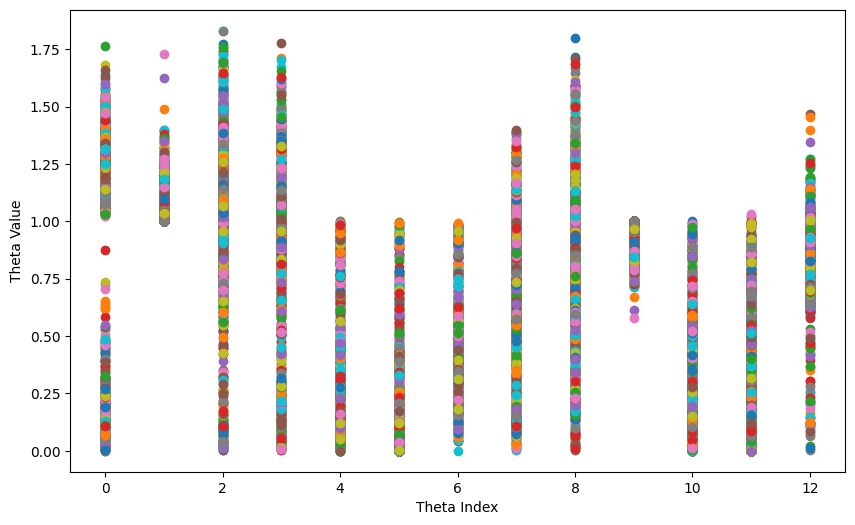

In [107]:
theta_opt.shape
plt.figure(figsize=(10, 6))
for i in range(no_samples):
    plt.plot(theta_opt[i, :], 'o', label=f'Sample {i+1}')
plt.xlabel('Theta Index')
plt.ylabel('Theta Value')
plt.show()


In [ ]:
plt.figure(figsize=(8, 6))

# keep track of the line objects so we can get their colors
lines = []

for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    line, = plt.plot(steps, loss_hist, 'o-', linewidth=2, markersize=4)
    lines.append(line)  # store line object

plt.xlabel('Iteration', fontsize=22)
plt.ylabel('Loss', fontsize=22)
plt.yscale('log')
#plt.xlim(0, 500)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)

# create legend using the colors of the actual plotted lines
#legend_handles = [Patch(color=line.get_color(), label=f'Set {i+1}')
#                  for i, line in enumerate(lines)]
#plt.legend(handles=legend_handles,loc='upper right',  fontsize=18)

plt.xlim(0, 800)
plt.tight_layout()
plt.savefig('Figures_final/one_op_loss_convergence.eps')
plt.show()


In [ ]:
###############################
# plot r, g, b, y for the operating point (x=1.0)
plt.figure(figsize=(16, 5))

neuron_types = ['Red (r)', 'Green (g)', 'Blue (b)', 'Mitral (y)']
outputs_list = [r_opt1, g_opt1, b_opt1, y_opt1]

for col, (neuron_type, output) in enumerate(zip(neuron_types, outputs_list)):
    plt.subplot(1, 4, col + 1)

    x_pos = np.arange(m)
    width = 0.8 / y_opt1.shape[0]

    for i in range(y_opt1.shape[0]):
        plt.bar(x_pos + i * width, np.array(output[i]), width,
                label=f'Sample {i+1}' if col == 0 else '', alpha=0.7)

    plt.axhline(y=t_op_high, color='red', linestyle='--', linewidth=1.5,
                alpha=0.5, label=f'Target ({t_op_high})')

    if col == 0:
        plt.ylabel('Firing Rate', fontsize=18)
        plt.tick_params(axis='y', labelsize=14)
    else:
        plt.tick_params(axis='y', labelleft=False)

    plt.xticks(x_pos + 100 * width, [f'Glom {j}' for j in range(m)], fontsize=12)
    plt.xlabel(f'{neuron_type}', fontsize=16)
    plt.title(f'x=1.0 — Target r,g,b,y={t_op_high}', fontsize=14)
    plt.ylim([0, 1.0])
    plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.savefig('Figures_final/one_op_neuron_outputs_rgby.eps')
plt.show()


In [ ]:
def check_single_theta_np(theta, m):
    """Op (x=1.0): r,g,b,y near t_op_high."""
    r1, g1, b1, y1 = mitral_output(theta, x1, m, n_r, n_b, n_y, n_g)

    def ok_band(arr, t):
        arr = np.array(arr)
        return (arr >= t - val_tol).all() and (arr <= t + val_tol).all()

    return (ok_band(r1, t_op_high) and ok_band(g1, t_op_high) and
            ok_band(b1, t_op_high) and ok_band(y1, t_op_high))

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]
print(theta_opt.shape)

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

# save theta_opt as pickle file
os.makedirs('Theta_opt', exist_ok=True)
fn = f'Theta_opt/theta_opt_{theta_opt.shape[0]}_1_point_final.pkl'
print(fn)
with open(
    fn,
    'wb',
) as f:
    pickle.dump(theta_opt, f)

## 4. see how params can change

In [ ]:
# Load theta_opt from pickle file
import glob
theta_opt_candidates = sorted(glob.glob('Theta_opt/theta_opt_*_1_point_final.pkl'))
theta_opt_file = theta_opt_candidates[-1]

with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt from {theta_opt_file}")
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Processing 214 samples...
  Sample 1/214...
  Sample 101/214...
  Sample 201/214...
Completed processing 214 samples


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


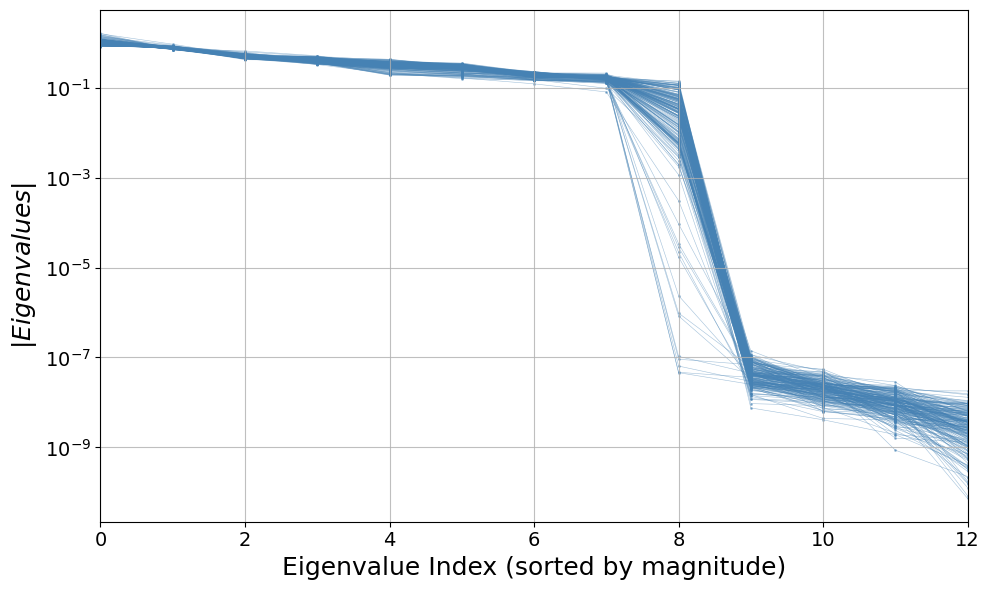

(214, 13, 13)

Array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]],      dtype=float32)

  Sample 1/214...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_897/726116112.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_897/726116112.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_897/726116112.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 

  Sample 101/214...
  Sample 201/214...


(212, 13)

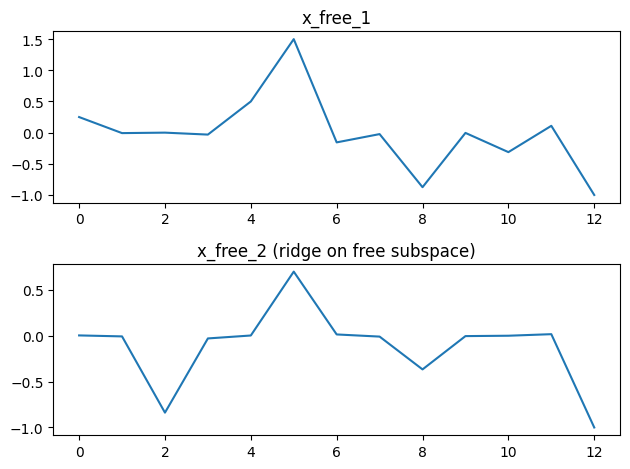

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


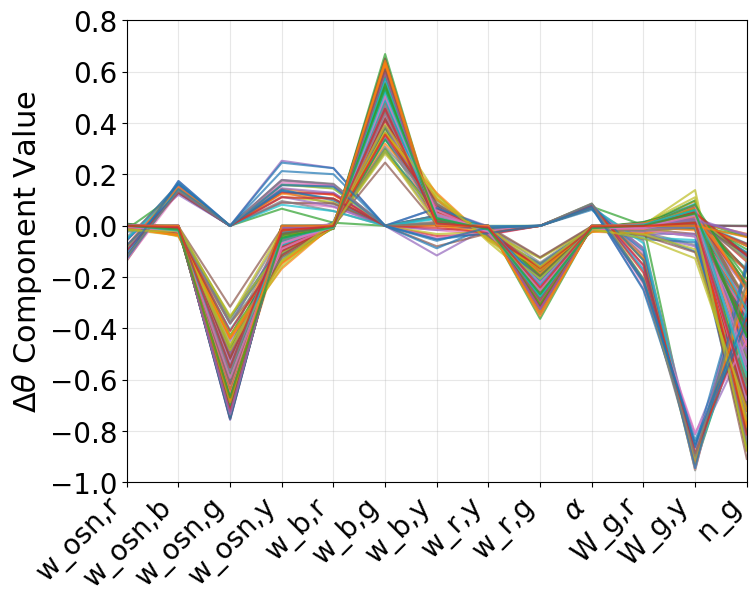

In [113]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=1.850, n_g=1.868, n_b=0.642, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r (n_g fixed, y_max_g scales the output)
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g) * y_max_g

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_g, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_g, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=1.850, n_g=1.868, n_b=0.642, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_g, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }

In [ ]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")

# Compute Hessian (1 op)

In [ ]:
x = jnp.array([1.0, 1.0])

In [ ]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y, n_g)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.5, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_xlim(0, 12)
plt.tight_layout()
plt.savefig(f'Figures_final/one_op_hessian_eigenvalues.eps')
plt.show()

In [117]:
all_eigenvectors.shape

(563, 13, 13)

In [118]:
# Plot eigenvectors for eigenvalue rank by |lambda| (overlay all samples)
eig_rank = 8  # index in eigenvalues sorted by magnitude (0-based)
max_samples = None  # set to int to cap

n_samples = len(all_eigenvalues)
sample_indices = range(n_samples) if max_samples is None else range(min(n_samples, max_samples))

plotted = 0

for sample_idx in sample_indices:
    eigvals = np.asarray(all_eigenvalues[sample_idx])
    eigvecs = np.asarray(all_eigenvectors[sample_idx])  # columns are eigenvectors

    if eigvals.size <= eig_rank:
        print(f"Sample {sample_idx}: only {eigvals.size} eigenvalues; skipping rank {eig_rank}")
        continue

    sorted_idx = np.argsort(np.abs(eigvals))
    k = int(sorted_idx[eig_rank])
    v = eigvecs[:, k]


In [119]:
v = jnp.zeros(n_params)
v = v.at[12].set(1)
v@v.T
v[:, None] * v[None, :]

Array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]],      dtype=float32)

In [120]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y, n_g)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]

v = jnp.zeros(n_params)
v = v.at[12].set(-1)

x_collect = []
for i in range(n_samples):
#for i in range(3):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])
    H2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H

    x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
    x_collect.append(x_free_1 + v)

x_collect = jnp.array(x_collect)



  Sample 1/563...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6)

  Sample 101/563...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6)

  Sample 201/563...


...

/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6)

  Sample 401/563...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6)

  Sample 501/563...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_89500/223761747.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6)

In [121]:
x_collect[2:].shape

(561, 13)

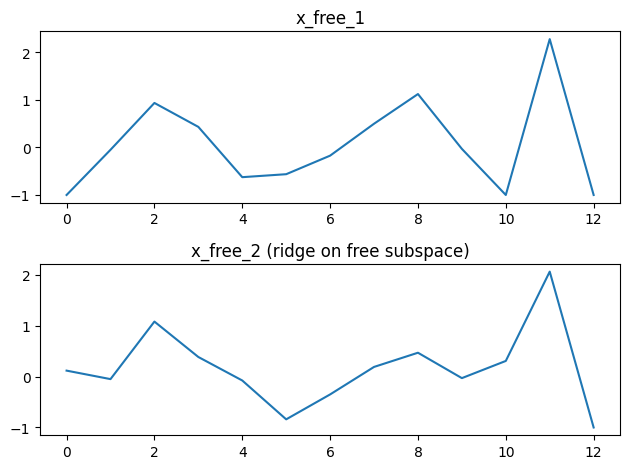

In [122]:
v = jnp.zeros(n_params)
v = v.at[12].set(-1)

# Projector onto the "free" subspace (orthogonal to v)
P = jnp.eye(n_params) - v[:, None] * v[None, :]

# let H1 = P^T H P (P is symmetric)
H1 = P @ H @ P

# let H2 = P H
H2 = P @ H

b = H2 @ v

# Baseline: pseudoinverse solution in the free subspace
x_free_1 = - jnp.linalg.pinv(H1, rtol=1e-8) @ b

####################
# Proper regularization for this construction:
# - H1 is singular along v by design (because of P)
# - adding eps*I changes the constrained direction too
# So we ridge only on the free subspace via (ridge * P)
# and solve with lstsq for robustness. 
eps = 1e-5
scale = (jnp.linalg.norm(H1, ord="fro") / jnp.sqrt(n_params)) + 1e-12
ridge = eps * scale
A = H1 + ridge * P

x_free_2 = - jnp.linalg.lstsq(A, b, rcond=None)[0]

# Ensure x is in the free subspace (numerical cleanup)
x_free_2 = P @ x_free_2

fig, axs = plt.subplots(2, 1)
axs[0].plot(x_free_1 + v)
axs[0].set_title("x_free_1")
axs[1].plot(x_free_2 + v)
axs[1].set_title("x_free_2 (ridge on free subspace)")

plt.tight_layout()
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


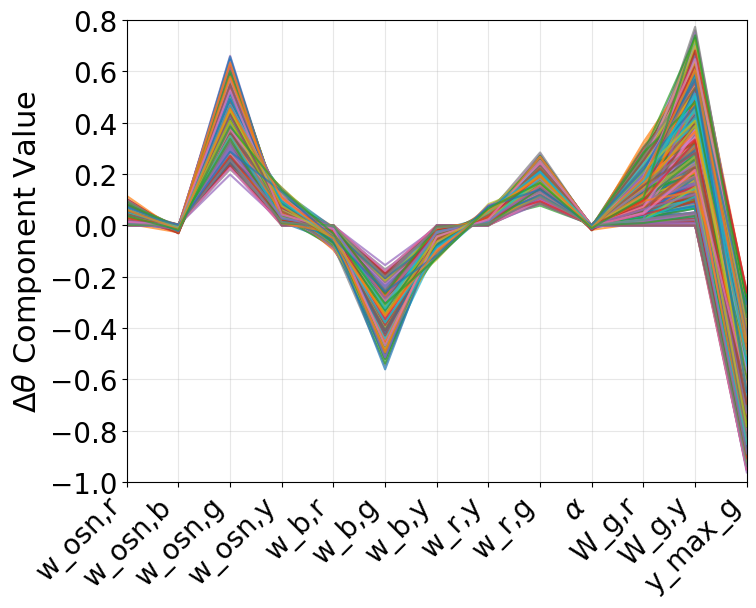

In [123]:
#plot all x_collect, each row is a different colour

x_collect = x_collect / jnp.linalg.norm(x_collect, axis=1, keepdims=True)

param_labels = [
    'w_osn,r', 'w_osn,b', 'w_osn,g', 'w_osn,y',
    'w_b,r', 'w_b,g', 'w_b,y', 'w_r,y', 'w_r,g',
    r"$\alpha$", 'W_g,r', 'W_g,y', 'y_max_g',
]

x_collect_np = np.array(x_collect)
indices = np.arange(len(param_labels))

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_np.shape[0]):
    plt.plot(indices, x_collect_np[row_idx], alpha=0.7)

plt.ylabel(r"$\Delta\theta$ Component Value", fontsize=22)
plt.xlim(0, 12)
plt.ylim(-1, 0.8)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.savefig(f'Figures_final/x_collect_all.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


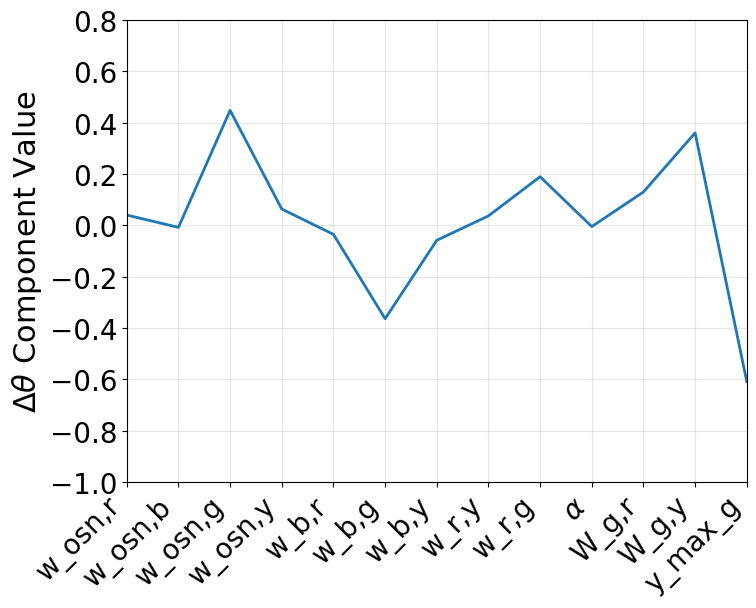

In [127]:
# Mean Δθ component profile (same filter as above)
mean_components = x_collect.mean(axis=0)

plt.figure(figsize=(8, 6))
plt.plot(indices, mean_components, linewidth=2)

plt.ylabel(r"$\Delta\theta$ Component Value", fontsize=22)
plt.xlim(0, 12)
plt.ylim(-1, 0.8)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.savefig('Figures_final/x_collect_wbg_ng_average.eps')
plt.show()